# Qwen3.6-27B Zero-Shot Evaluation

## 1. Model & Experiment Overview

Qwen3.6-27B is a 27-billion-parameter generative model from the Qwen family. In this experiment, it received a single instruction and a math word problem and generated an `ANSWERABLE` or `UNANSWERABLE` label based on the information in the question. The task was zero-shot, with no demonstrations or task-specific fine-tuning. This notebook analyzes saved results.

SUM Test is the internal held-out split. UMWP and MATE are external benchmarks.

In [1]:
import hashlib
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'notebooks').is_dir() and (path / 'data/processed').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start from the CDS1092 project root or notebooks directory.')

RESULTS_DIR = PROJECT_ROOT / 'results/llm/qwen3.6-27b'
RUN_ID = 'run_01'
LABELS = ['ANSWERABLE', 'UNANSWERABLE']
PREDICTED_LABELS = [*LABELS, 'INVALID']
METRICS = {
    'Accuracy': 'accuracy',
    'Precision (UNANSWERABLE)': 'precision_unanswerable',
    'Recall (UNANSWERABLE)': 'recall_unanswerable',
    'F1 (UNANSWERABLE)': 'f1_unanswerable',
}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def load_evaluation(dataset, expected_examples):
    directory = RESULTS_DIR / dataset / RUN_ID
    metrics = json.loads((directory / 'metrics.json').read_text(encoding='utf-8'))
    matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col='true_label')
    run = metrics['run']
    benchmark = PROJECT_ROOT / 'data/processed' / dataset / 'test.csv'
    digest = hashlib.sha256(benchmark.read_bytes().replace(b'\r\n', b'\n')).hexdigest()
    if run['dataset_sha256'] != digest:
        raise ValueError(f'{directory}: benchmark fingerprint differs')

    if (run['dataset'], run['run_id'], metrics['positive_class']) != (dataset, RUN_ID, LABELS[1]):
        raise ValueError(f'{directory}: unexpected run identity or positive class')
    if (list(matrix.index) != LABELS or list(matrix.columns) != PREDICTED_LABELS
            or metrics['confusion_matrix_rows'] != LABELS
            or metrics['confusion_matrix_columns'] != PREDICTED_LABELS):
        raise ValueError(f'{directory}: unexpected matrix labels or order')
    if (not all(pd.api.types.is_integer_dtype(dtype) for dtype in matrix.dtypes)
            or (matrix < 0).any().any() or matrix.values.tolist() != metrics['confusion_matrix']):
        raise ValueError(f'{directory}: CSV and JSON confusion counts disagree or are invalid')
    if not (matrix.values.sum() == metrics['num_examples'] == run['row_count'] == expected_examples):
        raise ValueError(f'{directory}: unexpected number of examples')

    tn, fp, invalid_negative = matrix.loc[LABELS[0]]
    fn, tp, invalid_positive = matrix.loc[LABELS[1]]
    missed = fn + invalid_positive

    def ratio(numerator, denominator):
        return numerator / denominator if denominator else 0.0

    expected = {
        'accuracy': (tn + tp) / expected_examples,
        'precision_unanswerable': ratio(tp, tp + fp),
        'recall_unanswerable': ratio(tp, tp + missed),
        'f1_unanswerable': ratio(2 * tp, 2 * tp + fp + missed),
        'num_invalid': invalid_negative + invalid_positive,
        'invalid_rate': (invalid_negative + invalid_positive) / expected_examples,
    }
    for key, value in expected.items():
        if not math.isclose(metrics[key], value, rel_tol=0, abs_tol=1e-12):
            raise ValueError(f'{directory}: {key} disagrees with the saved confusion counts')
    return metrics, matrix


sum_metrics, sum_matrix = load_evaluation('sum', 10944)
umwp_metrics, umwp_matrix = load_evaluation('umwp', 5200)
mate_metrics, mate_matrix = load_evaluation('mate', 9586)

In [2]:
settings = {
    'Model': 'model_id',
    'Weights path': 'model_path',
    'Chat template': 'chat_template',
    'Precision': 'dtype',
    'Quantization': 'quantization',
    'GPU': 'gpu',
    'Requested temperature': 'requested_temperature',
    'Sampling enabled': 'do_sample',
    'Number of beams': 'num_beams',
    'Maximum new tokens': 'max_new_tokens',
    'PyTorch': 'torch_version',
    'Transformers': 'transformers_version',
    'CUDA': 'cuda_version',
}
run = sum_metrics['run']
for key in (*settings.values(), 'prompt', 'model_sha256', 'invalid_output_policy'):
    if any(run[key] != metrics['run'][key] for metrics in (umwp_metrics, mate_metrics)):
        raise ValueError(f'Saved runs disagree on {key}')

configuration = {
    label: 'None' if run[key] is None else str(run[key])
    for label, key in settings.items()
}
configuration['Decoding'] = 'Greedy' if not run['do_sample'] and run['num_beams'] == 1 else 'See settings'
display(pd.Series(configuration, name='Recorded setting').rename_axis('Setting').to_frame())
display(Markdown('**Exact prompt**\n\n```text\n' + run['prompt'] + '\n```'))
provenance = pd.DataFrame([
    {'Dataset': name, 'Dataset SHA-256': metrics['run']['dataset_sha256'],
     'Model SHA-256': metrics['run']['model_sha256'],
     'Evaluator SHA-256': metrics['run']['evaluator_sha256'],
     'Shared evaluator SHA-256': metrics['run'].get('shared_evaluator_sha256', 'N/A')}
    for name, metrics in [('SUM Test', sum_metrics), ('UMWP', umwp_metrics), ('MATE', mate_metrics)]
]).set_index('Dataset')
display(provenance)
display(Markdown('The MATE run records a later evaluator fingerprint. Model and protocol settings above agree across the saved runs.'))

,Recorded setting
Setting,
Model,Qwen/Qwen3.6-27B
Weights path,models/Qwen3.6-27B
Chat template,"model default, user message only, enable_think..."
Precision,bfloat16
Quantization,None
GPU,NVIDIA A100 80GB PCIe
Requested temperature,0
Sampling enabled,False
Number of beams,1


**Exact prompt**

```text
Determine whether the following math problem can be answered using the information provided.

Respond with exactly one label:
ANSWERABLE or UNANSWERABLE.

Do not solve the problem or provide an explanation.

Math problem:
{question}

Label:
```

,Dataset SHA-256,Model SHA-256,Evaluator SHA-256,Shared evaluator SHA-256
Dataset,,,,
SUM Test,c1e4bac1e1d1f27ab8a6408ac68ae710faf521822bff49...,16298e055beee94c167be3e842570c20fe919a2acaa997...,292e98e5db749939399e3fea2a6279fd99648160577d96...,N/A
UMWP,92df3bed2d3cee139c6ddbca2673fca0a1687aa9f90b3c...,16298e055beee94c167be3e842570c20fe919a2acaa997...,292e98e5db749939399e3fea2a6279fd99648160577d96...,N/A
MATE,377f7a28a6b2a5236ce24eeebc889c99ec38ff92c52c9b...,16298e055beee94c167be3e842570c20fe919a2acaa997...,9a1a360dc9f154d3b71910a8370377b4138e99529728d9...,N/A


The MATE run records a later evaluator fingerprint. Model and protocol settings above agree across the saved runs.

## 2. Evaluation Metrics

**UNANSWERABLE is the positive class.**

- **Accuracy** is the fraction of all questions assigned the correct label.
- **Precision** is the fraction of predicted UNANSWERABLE questions that are truly unanswerable.
- **Recall** is the fraction of truly unanswerable questions detected by the model.
- **F1** is the harmonic mean of precision and recall for UNANSWERABLE.

Confusion matrices show actual labels in rows and predicted labels in columns. A false positive flags an answerable question as unanswerable. A false negative marks an unanswerable question as answerable, which can lead a downstream solver to attempt a question with insufficient information. The INVALID column tracks responses outside the two permitted labels. Each heatmap scales its colors to its own counts.

In [3]:
if any(sum_metrics['invalid_output_policy'] != m['invalid_output_policy'] for m in (umwp_metrics, mate_metrics)):
    raise ValueError('Saved runs disagree on the invalid-output policy')
display(Markdown('**Recorded scoring policy.** ' + sum_metrics['invalid_output_policy']))


def show_evaluation(name, metrics, matrix):
    summary = {
        'Examples': f"{metrics['num_examples']:,}",
        **{label: f'{metrics[key]:.2%}' for label, key in METRICS.items()},
        'Invalid outputs': f"{metrics['num_invalid']:,} ({metrics['invalid_rate']:.2%})",
    }
    display(pd.DataFrame([summary], index=pd.Index([name], name='Dataset')))

    fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
    values = matrix.to_numpy()
    limit = values.max()
    ax.imshow(values, cmap='Blues', vmin=0, vmax=limit, aspect='auto')
    for (row, column), value in matrix.stack().items():
        ax.text(matrix.columns.get_loc(column), matrix.index.get_loc(row), f'{value:,}',
                ha='center', va='center', color='white' if value > limit / 2 else 'black')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted label', ylabel='Actual label', title=f'{name} confusion matrix')
    plt.show()
    plt.close(fig)


def describe_errors(matrix):
    fp = matrix.loc['ANSWERABLE', 'UNANSWERABLE']
    fn = matrix.loc['UNANSWERABLE', 'ANSWERABLE']
    answerable = matrix.loc['ANSWERABLE'].sum()
    unanswerable = matrix.loc['UNANSWERABLE'].sum()
    return (
        f'The model flagged **{fp:,}** answerable problems as unanswerable '
        f'({fp / answerable:.2%} of answerable problems). It marked **{fn:,}** unanswerable '
        f'problems as answerable ({fn / unanswerable:.2%} of unanswerable problems).'
    )

**Recorded scoring policy.** After trimming surrounding whitespace, only exact uppercase labels are valid. INVALID is incorrect for accuracy and is a separate confusion-matrix column. INVALID on a true UNANSWERABLE row counts as a missed positive for recall and F1. Precision uses all predicted UNANSWERABLE rows. Zero denominators yield zero.

## 3. SUM Results & Analysis

SUM Test is the held-out split of the Synthetic Unanswerable Math benchmark. The analysis uses the complete saved test run.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
SUM Test,"10,944",88.10%,90.87%,84.72%,87.69%,0 (0.00%)


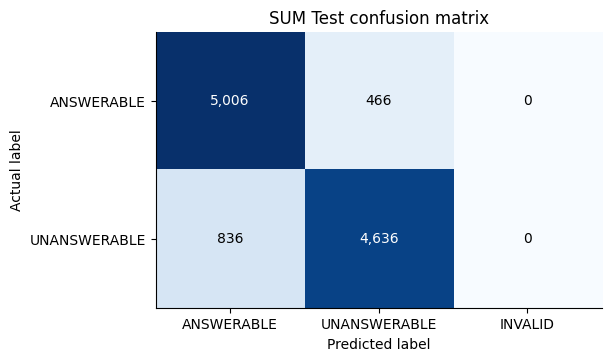

Accuracy on SUM Test was **88.10%**, with an UNANSWERABLE F1 of **87.69%**. The model flagged **466** answerable problems as unanswerable (8.52% of answerable problems). It marked **836** unanswerable problems as answerable (15.28% of unanswerable problems). UNANSWERABLE precision was 90.87%, while recall was 84.72%. The observed errors suggest that treating a problem as answerable is the more frequent misclassification on this split.

In [4]:
show_evaluation('SUM Test', sum_metrics, sum_matrix)
display(Markdown(
    f"Accuracy on SUM Test was **{sum_metrics['accuracy']:.2%}**, with an UNANSWERABLE "
    f"F1 of **{sum_metrics['f1_unanswerable']:.2%}**. {describe_errors(sum_matrix)} "
    f"UNANSWERABLE precision was {sum_metrics['precision_unanswerable']:.2%}, "
    f"while recall was {sum_metrics['recall_unanswerable']:.2%}. "
    'The observed errors suggest that treating a problem as answerable is the more '
    'frequent misclassification on this split.'
))

## 4. UMWP Results & Analysis

UMWP is an external mathematical word problem benchmark. The analysis uses the complete saved UMWP run.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
UMWP,"5,200",93.19%,94.11%,92.15%,93.12%,0 (0.00%)


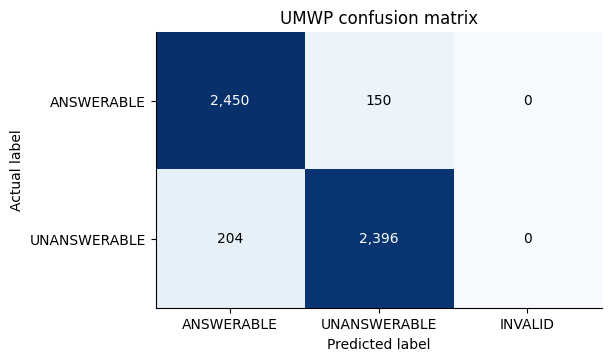

Accuracy on UMWP was **93.19%**, with an UNANSWERABLE F1 of **93.12%**. The model flagged **150** answerable problems as unanswerable (5.77% of answerable problems). It marked **204** unanswerable problems as answerable (7.85% of unanswerable problems). The model correctly flagged 92.15% of truly unanswerable questions. Of the questions it flagged, 94.11% were truly unanswerable. The missed detections quantify the risk of passing an unanswerable problem to a solver.

In [5]:
show_evaluation('UMWP', umwp_metrics, umwp_matrix)
display(Markdown(
    f"Accuracy on UMWP was **{umwp_metrics['accuracy']:.2%}**, with an UNANSWERABLE "
    f"F1 of **{umwp_metrics['f1_unanswerable']:.2%}**. {describe_errors(umwp_matrix)} "
    f"The model correctly flagged {umwp_metrics['recall_unanswerable']:.2%} of truly "
    f"unanswerable questions. Of the questions it flagged, "
    f"{umwp_metrics['precision_unanswerable']:.2%} were truly unanswerable. "
    'The missed detections quantify the risk of passing an unanswerable problem to a solver.'
))

## 5. MATE Results & Analysis

MATE is the second external benchmark. The analysis uses the complete saved run on the fixed processed test file.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
MATE,"9,586",84.58%,89.36%,78.51%,83.59%,0 (0.00%)


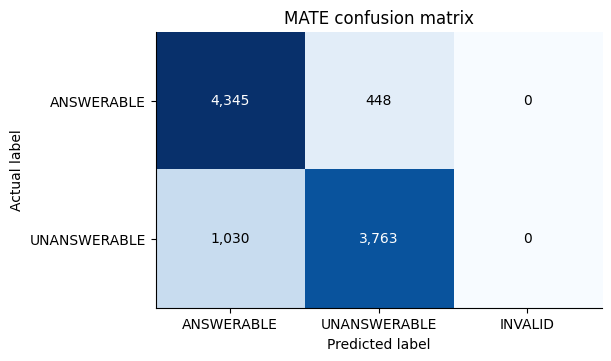

The model flagged **448** answerable problems as unanswerable (9.35% of answerable problems). It marked **1,030** unanswerable problems as answerable (21.49% of unanswerable problems).

In [6]:
show_evaluation('MATE', mate_metrics, mate_matrix)
display(Markdown(describe_errors(mate_matrix)))

## 6. Dataset Comparison & Interpretation

,ANSWERABLE,UNANSWERABLE,INVALID
Dataset,,,
SUM Test,5842 (53.38%),5102 (46.62%),0 (0.00%)
UMWP,2654 (51.04%),2546 (48.96%),0 (0.00%)
MATE,5375 (56.07%),4211 (43.93%),0 (0.00%)


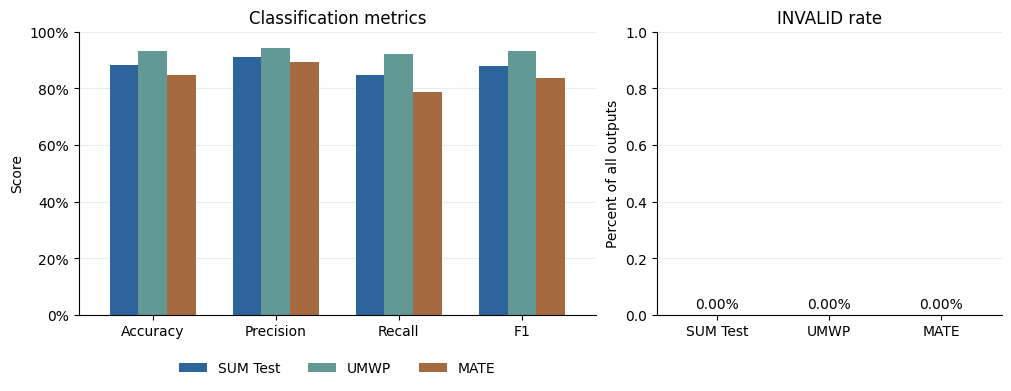

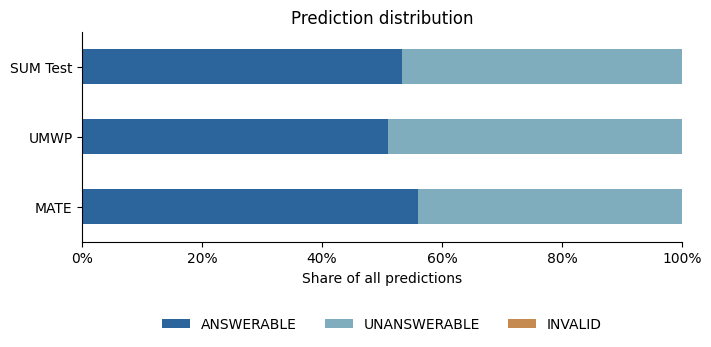

In [7]:
evaluations = {'SUM Test': (sum_metrics, sum_matrix), 'UMWP': (umwp_metrics, umwp_matrix), 'MATE': (mate_metrics, mate_matrix)}
metric_rates = pd.DataFrame({
    name: {label: metrics[key] for label, key in METRICS.items()}
    for name, (metrics, _) in evaluations.items()
})
metric_rates.index = ['Accuracy', 'Precision', 'Recall', 'F1']
invalid_rates = pd.Series({name: metrics['invalid_rate'] for name, (metrics, _) in evaluations.items()})
prediction_counts = pd.DataFrame({
    name: matrix.sum(axis=0) for name, (_, matrix) in evaluations.items()
}).T
prediction_shares = prediction_counts.div(prediction_counts.sum(axis=1), axis=0)
display((prediction_counts.astype(str) + ' (' + prediction_shares.map('{:.2%}'.format) + ')')
        .rename_axis('Dataset'))

colors = ['#2b659b', '#629995', '#a66a41']
fig, (ax_metrics, ax_invalid) = plt.subplots(
    1, 2, figsize=(10, 3.8), width_ratios=[3, 2], layout='constrained',
)
metric_rates.plot.bar(ax=ax_metrics, color=colors, rot=0, width=0.7)
ax_metrics.set(ylim=(0, 1), ylabel='Score', title='Classification metrics')
ax_metrics.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax_metrics.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
invalid_bars = ax_invalid.bar(invalid_rates.index, invalid_rates * 100, color=colors)
ax_invalid.bar_label(invalid_bars, labels=[f'{rate:.2%}' for rate in invalid_rates], padding=3)
ax_invalid.set(ylim=(0, 1), ylabel='Percent of all outputs', title='INVALID rate')
for ax in (ax_metrics, ax_invalid):
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.25)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 3.3), layout='constrained')
prediction_shares.plot.barh(ax=ax, stacked=True, color=['#2b659b', '#80adbd', '#c58a50'])
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel='Share of all predictions', ylabel='', title='Prediction distribution')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
plt.show()
plt.close(fig)

In [8]:
observations = []
for name, (metrics, matrix) in evaluations.items():
    answerable_share = prediction_shares.loc[name, 'ANSWERABLE']
    observations.append(
        f"- **{name}**: {answerable_share:.2%} of predictions were ANSWERABLE. "
        f"UNANSWERABLE precision was {metrics['precision_unanswerable']:.2%} and "
        f"recall was {metrics['recall_unanswerable']:.2%}. "
        f"The matrix records {matrix.loc['UNANSWERABLE', 'ANSWERABLE']:,} false negatives "
        f"and {matrix.loc['ANSWERABLE', 'UNANSWERABLE']:,} false positives."
    )
for target, reference in [('UMWP', 'SUM Test'), ('MATE', 'SUM Test'), ('MATE', 'UMWP')]:
    gap = 100 * (evaluations[target][0]['f1_unanswerable'] - evaluations[reference][0]['f1_unanswerable'])
    observations.append(f"- UNANSWERABLE F1 on {target} versus {reference}: {gap:+.2f} percentage points.")
display(Markdown("\n".join(observations)))

- **SUM Test**: 53.38% of predictions were ANSWERABLE. UNANSWERABLE precision was 90.87% and recall was 84.72%. The matrix records 836 false negatives and 466 false positives.
- **UMWP**: 51.04% of predictions were ANSWERABLE. UNANSWERABLE precision was 94.11% and recall was 92.15%. The matrix records 204 false negatives and 150 false positives.
- **MATE**: 56.07% of predictions were ANSWERABLE. UNANSWERABLE precision was 89.36% and recall was 78.51%. The matrix records 1,030 false negatives and 448 false positives.
- UNANSWERABLE F1 on UMWP versus SUM Test: +5.43 percentage points.
- UNANSWERABLE F1 on MATE versus SUM Test: -4.10 percentage points.
- UNANSWERABLE F1 on MATE versus UMWP: -9.54 percentage points.